In [1]:
print("Let's build a trustworthy baseline model first from what we learned?")

Let's build a trustworthy baseline model first from what we learned?


In [38]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

%matplotlib inline

In [11]:
ds = pd.read_csv('../raw/default_of_credit_card_clients.csv')
df = ds

In [12]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [13]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [14]:
customer_repays = [
    'pay_0',
    'pay_2',
    'pay_3', 
    'pay_4', 
    'pay_5', 
    'pay_6'
]

In [15]:
# Create num_delayed_months

# Assuming:
# PAY >= 1 → delayed
# PAY <= 0 → not delayed

df["num_delayed_months"] = (df[customer_repays] > 0).sum(axis=1)

In [16]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month,num_delayed_months
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,689,0,0,0,0,1,2
1,2,120000,2,2,2,26,-1,2,0,0,...,3455,3261,0,1000,1000,1000,0,2000,1,2
2,3,90000,2,2,2,34,0,0,0,0,...,14948,15549,1518,1500,1000,1000,1000,5000,0,0
3,4,50000,2,2,1,37,0,0,0,0,...,28959,29547,2000,2019,1200,1100,1069,1000,0,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,19146,19131,2000,36681,10000,9000,689,679,0,0


In [2]:
# Candidate Features:

# For the first baseline, I recommend keeping the feature set relatively straightforward.

In [17]:
# Customer Characterstics

profile_features = [
    "limit_bal",
    "sex",
    "education",
    "marriage",
    "age"
]

In [18]:
# Repayment History

repayment_features = [
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

In [5]:
# Bill History

bill_features = [
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6"
]

In [19]:
# Payment History

payment_features = [
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6"
]

In [20]:
# One engineered behavioral feature

"num_delayed_months"

'num_delayed_months'

In [21]:
candidate_features = (
    profile_features
    + repayment_features
    + bill_features
    + payment_features
    + ["num_delayed_months"]
)

In [ ]:
# Train / Validation / Test Strategy

In [22]:
# Stratification

# For this project, I like 64/16/20 because it gives us a reasonably large final test set 
# while preserving enough training data.


In [23]:
target = "default_payment_next_month"

X = df[candidate_features].copy()
y = df[target].copy()

In [26]:
X.shape

(30000, 24)

In [51]:
X.head()

,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,pay_5,...,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,num_delayed_months
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,2
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,2
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [27]:
# Split the data

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [28]:
# Again split the remaining 80%

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val
)

In [29]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (19200, 24)
Validation: (4800, 24)
Test: (6000, 24)


In [30]:
# Verify target distribution

print("Full dataset:")
print(y.value_counts(normalize=True))

print("\nTrain:")
print(y_train.value_counts(normalize=True))

print("\nValidation:")
print(y_val.value_counts(normalize=True))

print("\nTest:")
print(y_test.value_counts(normalize=True))

Full dataset:
default_payment_next_month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

Train:
default_payment_next_month
0    0.778802
1    0.221198
Name: proportion, dtype: float64

Validation:
default_payment_next_month
0    0.77875
1    0.22125
Name: proportion, dtype: float64

Test:
default_payment_next_month
0    0.778833
1    0.221167
Name: proportion, dtype: float64


In [39]:
# Numerical

numerical_features = [
    "limit_bal",
    "age",

    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6",

    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6",

    "num_delayed_months"
]

In [40]:
# Numerical

categorical_features = [
    "sex",
    "education",
    "marriage",
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

In [34]:
# Build the preprocessing pipeline

In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [42]:
# Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [36]:
# Train the first Logistic Regression

In [43]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['limit_bal','sex','education',...,'pay_amt5','pay_amt6', 'num_delayed_months']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

In [44]:
y_pred = model.predict(X_val)
y_pred_proba = model.predict_proba(X_val)[:, 1]

In [45]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(4800,))

In [46]:
y_pred_proba

array([0.23829896, 0.41104634, 0.10290637, ..., 0.41023896, 0.10577603,
       0.06377428], shape=(4800,))

In [47]:
accuracy = accuracy_score(y_val, y_pred)

precision = precision_score(y_val, y_pred)

recall = recall_score(y_val, y_pred)

f1 = f1_score(y_val, y_pred)

roc_auc = roc_auc_score(y_val, y_pred_proba)

In [48]:
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.8187
Precision: 0.6784
Recall:    0.3437
F1 Score:  0.4562
ROC-AUC:   0.7603


In [49]:
# Confusion matrix

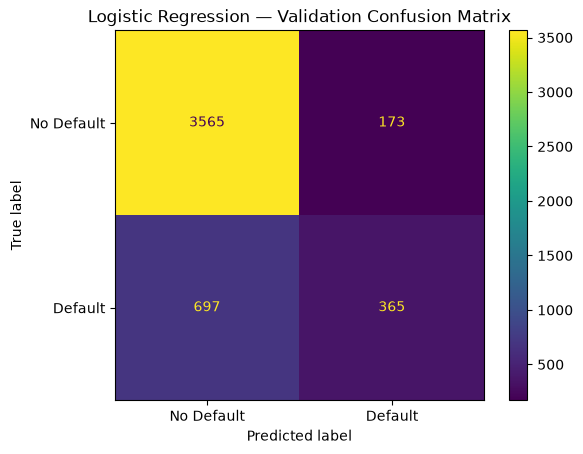

In [50]:

cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot()
plt.title("Logistic Regression — Validation Confusion Matrix")
plt.show()

In [52]:
print(cm)

[[3565  173]
 [ 697  365]]


In [56]:
tn, fp, fn, tp = confusion_matrix(
    y_val,
    y_pred
).ravel()

print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:   {tp}")

print(f"Actual defaulters:        {fn + tp}")
print(f"Correctly identified:    {tp}")
print(f"Missed defaulters:        {fn}")

True Negatives:  3565
False Positives: 173
False Negatives: 697
True Positives:   365
Actual defaulters:        1062
Correctly identified:    365
Missed defaulters:        697


In [55]:
baseline_results = pd.DataFrame({
    "model": ["Logistic Regression"],
    "accuracy": [accuracy],
    "precision": [precision],
    "recall": [recall],
    "f1": [f1],
    "roc_auc": [roc_auc],
    "confusion_matrix": [cm]
})

baseline_results

,model,accuracy,precision,recall,f1,roc_auc,confusion_matrix
0,Logistic Regression,0.81875,0.678439,0.343691,0.45625,0.76027,"[[3565, 173], [697, 365]]"


In [57]:
# Feature Engineering Experimentation

In [ ]:
# Feature Group 1 — Delinquency Severity

# Q: How severe was the customer's repayment behavior?
# Q: How serious was the customer's repayment problem?

In [108]:
# Note:

# Modeling assumption:
# PAY >= 2 is treated as a higher-severity repayment status
# for this feature-engineering experiment.

In [59]:
# Candidate Feature: Maximum Delinquency Severity

# max_delay_severity = max(pay_0, pay_2, pay_3, pay_4, pay_5, pay_6)

# This answers:
# What was the most severe repayment-status value observed for this customer?


In [61]:
pay_columns = [
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

df["max_delay_severity"] = df[pay_columns].max(axis=1)

In [63]:
df["max_delay_severity"]

0        2
1        2
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    4
29998    1
29999    0
Name: max_delay_severity, Length: 30000, dtype: int64

In [62]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month,num_delayed_months,max_delay_severity
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,689,0,0,0,0,1,2,2
1,2,120000,2,2,2,26,-1,2,0,0,...,3261,0,1000,1000,1000,0,2000,1,2,2
2,3,90000,2,2,2,34,0,0,0,0,...,15549,1518,1500,1000,1000,1000,5000,0,0,0
3,4,50000,2,2,1,37,0,0,0,0,...,29547,2000,2019,1200,1100,1069,1000,0,0,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,19131,2000,36681,10000,9000,689,679,0,0,0


In [66]:
# Candidate Feature: Average Repayment Status

# avg_delay_severity

# This captures the customer's average repayment-status level across the observed months.

In [65]:
df["avg_delay_severity"] = df[pay_columns].mean(axis=1)

In [67]:
df["avg_delay_severity"]

0       -0.333333
1        0.500000
2        0.000000
3        0.000000
4       -0.333333
           ...   
29995    0.000000
29996   -0.666667
29997    1.333333
29998   -0.166667
29999    0.000000
Name: avg_delay_severity, Length: 30000, dtype: float64

In [68]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month,num_delayed_months,max_delay_severity,avg_delay_severity
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,689,0,0,0,0,1,2,2,-0.333333
1,2,120000,2,2,2,26,-1,2,0,0,...,0,1000,1000,1000,0,2000,1,2,2,0.500000
2,3,90000,2,2,2,34,0,0,0,0,...,1518,1500,1000,1000,1000,5000,0,0,0,0.000000
3,4,50000,2,2,1,37,0,0,0,0,...,2000,2019,1200,1100,1069,1000,0,0,0,0.000000
4,5,50000,1,2,1,57,-1,0,-1,0,...,2000,36681,10000,9000,689,679,0,0,0,-0.333333


In [71]:
# Candidate Feature: Total Delinquency Severity

# total_delay_severity

# We can calculate the total positive repayment-status severity

# The .clip(lower=0) is important.
# We don't want values such as -2 or -1 to contribute negatively to the severity score.

In [72]:
df["total_delay_severity"] = (
    df[pay_columns]
    .clip(lower=0)
    .sum(axis=1)
)

In [73]:
df["total_delay_severity"]

0        4
1        4
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    9
29998    1
29999    0
Name: total_delay_severity, Length: 30000, dtype: int64

In [74]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month,num_delayed_months,max_delay_severity,avg_delay_severity,total_delay_severity
0,1,20000,2,2,1,24,2,2,-1,-1,...,689,0,0,0,0,1,2,2,-0.333333,4
1,2,120000,2,2,2,26,-1,2,0,0,...,1000,1000,1000,0,2000,1,2,2,0.500000,4
2,3,90000,2,2,2,34,0,0,0,0,...,1500,1000,1000,1000,5000,0,0,0,0.000000,0
3,4,50000,2,2,1,37,0,0,0,0,...,2019,1200,1100,1069,1000,0,0,0,0.000000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,36681,10000,9000,689,679,0,0,0,-0.333333,0


In [75]:
# Candidate Feature: Number of Severe Delinquencies

# We can go one step further and ask:
# Q: How many months had relatively severe repayment status?

In [76]:
df["num_severe_delays"] = (
    df[pay_columns] >= 2
).sum(axis=1)

In [77]:
df["num_severe_delays"] 

0        2
1        2
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    3
29998    0
29999    0
Name: num_severe_delays, Length: 30000, dtype: int64

In [ ]:
# We now have:
# 1 - num_delayed_months:
# → frequency of any positive repayment status.

# 2 - num_severe_delays
# → frequency of repayment statuses ≥ 2.

In [78]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month,num_delayed_months,max_delay_severity,avg_delay_severity,total_delay_severity,num_severe_delays
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,1,2,2,-0.333333,4,2
1,2,120000,2,2,2,26,-1,2,0,0,...,1000,1000,0,2000,1,2,2,0.500000,4,2
2,3,90000,2,2,2,34,0,0,0,0,...,1000,1000,1000,5000,0,0,0,0.000000,0,0
3,4,50000,2,2,1,37,0,0,0,0,...,1200,1100,1069,1000,0,0,0,0.000000,0,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,10000,9000,689,679,0,0,0,-0.333333,0,0


In [79]:
# Our First Feature Group
# For Experiment 1, let's therefore test:

In [80]:
delinquency_features = [
    "max_delay_severity",
    "avg_delay_severity",
    "total_delay_severity",
    "num_severe_delays"
]

In [81]:
# Inspect the new feature group constructed:

In [82]:
df[
    [
        "max_delay_severity",
        "avg_delay_severity",
        "total_delay_severity",
        "num_severe_delays"
    ]
].describe()

,max_delay_severity,avg_delay_severity,total_delay_severity,num_severe_delays
count,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.438733,-0.182439,1.687700,0.710133
std,1.345154,0.982176,3.609322,1.464712
min,-2.000000,-2.000000,0.000000,0.000000
25%,0.000000,-0.833333,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,2.000000,0.000000,2.000000,1.000000
max,8.000000,6.000000,36.000000,6.000000


In [83]:
df[
    pay_columns + [
        "max_delay_severity",
        "avg_delay_severity",
        "total_delay_severity",
        "num_severe_delays"
    ]
].head(10)

,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6,max_delay_severity,avg_delay_severity,total_delay_severity,num_severe_delays
0,2,2,-1,-1,-2,-2,2,-0.333333,4,2
1,-1,2,0,0,0,2,2,0.500000,4,2
2,0,0,0,0,0,0,0,0.000000,0,0
3,0,0,0,0,0,0,0,0.000000,0,0
4,-1,0,-1,0,0,0,0,-0.333333,0,0
5,0,0,0,0,0,0,0,0.000000,0,0
6,0,0,0,0,0,0,0,0.000000,0,0
7,0,-1,-1,0,0,-1,0,-0.500000,0,0
8,0,0,2,0,0,0,2,0.333333,2,1
9,-2,-2,-2,-2,-1,-1,-1,-1.666667,0,0


In [84]:
# Important: Don't Immediately Assume They're Good Features
# This is a critical part of becoming an ML Engineer rather than simply creating features.

# We don't say:
# "This feature makes sense, therefore it must improve the model."

# Instead:
# "This feature represents a plausible business concept. Let's test whether it improves predictive performance."

# That's the mindset we want throughout this project.

In [85]:
# Build Experiment 1

In [86]:
candidate_features = (
    profile_features
    + repayment_features
    + bill_features
    + payment_features
    + ["num_delayed_months"]
)

In [87]:
severity_features = [
    "max_delay_severity",
    "avg_delay_severity",
    "total_delay_severity",
    "num_severe_delays"
]

In [88]:
experiment_features = (
    candidate_features
    + severity_features
)

In [89]:
X_exp1 = df[experiment_features].copy()
y_exp1 = df[target].copy()

In [91]:
# Very Important: Use the Same Split

In [90]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_exp1,
    y_exp1,
    test_size=0.20,
    random_state=42,
    stratify=y_exp1
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val
)

In [92]:
# Update the Preprocessing Lists

In [93]:
numerical_features = [
    "limit_bal",
    "age",
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6",
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6",
    "num_delayed_months",
    "max_delay_severity",
    "avg_delay_severity",
    "total_delay_severity",
    "num_severe_delays"
]

In [94]:
categorical_features = [
    "sex",
    "education",
    "marriage",
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

In [95]:
# Train the Same Logistic Regression

In [96]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [97]:
model_exp1 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [99]:
# Train

In [98]:
model_exp1.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['limit_bal','sex','education',...,'avg_delay_severity', 'total_delay_severity','num_severe_delays']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [100]:
# Predict

In [101]:
y_pred_exp1 = model_exp1.predict(X_val)

y_pred_proba_exp1 = model_exp1.predict_proba(
    X_val
)[:, 1]

In [102]:
# Evaluate Experiment 1
# Use exactly the same metrics as the baseline:

In [103]:
accuracy_exp1 = accuracy_score(
    y_val,
    y_pred_exp1
)

precision_exp1 = precision_score(
    y_val,
    y_pred_exp1
)

recall_exp1 = recall_score(
    y_val,
    y_pred_exp1
)

f1_exp1 = f1_score(
    y_val,
    y_pred_exp1
)

roc_auc_exp1 = roc_auc_score(
    y_val,
    y_pred_proba_exp1
)

In [104]:
print(f"Accuracy:  {accuracy_exp1:.4f}")
print(f"Precision: {precision_exp1:.4f}")
print(f"Recall:    {recall_exp1:.4f}")
print(f"F1 Score:  {f1_exp1:.4f}")
print(f"ROC-AUC:   {roc_auc_exp1:.4f}")

Accuracy:  0.8175
Precision: 0.6710
Recall:    0.3437
F1 Score:  0.4545
ROC-AUC:   0.7637


In [ ]:
# Compare Against the baseline

In [105]:
results = pd.DataFrame([
    {
        "experiment": "Baseline",
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    },
    {
        "experiment": "Exp 1 - Delinquency Severity",
        "accuracy": accuracy_exp1,
        "precision": precision_exp1,
        "recall": recall_exp1,
        "f1": f1_exp1,
        "roc_auc": roc_auc_exp1
    }
])

results

,experiment,accuracy,precision,recall,f1,roc_auc
0,Baseline,0.81875,0.678439,0.343691,0.456250,0.760270
1,Exp 1 - Delinquency Severity,0.81750,0.670956,0.343691,0.454545,0.763681


In [107]:
results["roc_auc_change"] = (
    results["roc_auc"] - results.loc[0, "roc_auc"]
)

results

,experiment,accuracy,precision,recall,f1,roc_auc,roc_auc_change
0,Baseline,0.81875,0.678439,0.343691,0.456250,0.760270,0.000000
1,Exp 1 - Delinquency Severity,0.81750,0.670956,0.343691,0.454545,0.763681,0.003411


In [109]:
# Note
# Experiment 1 — Interpretation:

# The delinquency severity features increased validation ROC-AUC from 0.76027 to 0.76368, 
# indicating a modest improvement in the model's ability to rank customers according to default risk. 
# However, accuracy, precision, and F1 decreased slightly, while recall remained unchanged at 0.34369. 
# Therefore, the feature group provides limited incremental predictive signal but does not 
# improve classification performance at the default 0.5 threshold. 
# The features will be retained as candidate features for subsequent experiments and evaluated again 
# as part of the final feature set.

In [110]:
# Feature Group 2 - Delinquency Persistence

In [111]:
# Experiment 2 — Delinquency Persistence.
# let's focus specifically on the structure of the repayment history.

# Q: How persistent was the customer's repayment problem?
# Q: How consistently or continuously did the repayment problem occur?

In [ ]:
# Candidate Feature - 1. Longest Consecutive Delinquency

# We want to calculate:
# The longest consecutive sequence of months where the customer had a delayed repayment status.

# this calculation depends on the sequence/order of the observations.
# We therefore create a reusable function.

In [112]:
def longest_consecutive_delays(row):
    max_streak = 0
    current_streak = 0

    for value in row:
        if value > 0:
            current_streak += 1
            max_streak = max(max_streak, current_streak)
        else:
            current_streak = 0

    return max_streak

In [113]:
# Then apply it across the repayment columns:

df["longest_delayed_streak"] = (
    df[pay_columns]
    .apply(longest_consecutive_delays, axis=1)
)

In [115]:
df["longest_delayed_streak"]

0        2
1        1
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    3
29998    1
29999    0
Name: longest_delayed_streak, Length: 30000, dtype: int64

In [116]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month,num_delayed_months,max_delay_severity,avg_delay_severity,total_delay_severity,num_severe_delays,longest_delayed_streak
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,1,2,2,-0.333333,4,2,2
1,2,120000,2,2,2,26,-1,2,0,0,...,1000,0,2000,1,2,2,0.500000,4,2,1
2,3,90000,2,2,2,34,0,0,0,0,...,1000,1000,5000,0,0,0,0.000000,0,0,0
3,4,50000,2,2,1,37,0,0,0,0,...,1100,1069,1000,0,0,0,0.000000,0,0,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,9000,689,679,0,0,0,-0.333333,0,0,0


In [117]:
# Candidate Feature - 2. Delinquency Persistence Ratio

# Calculate:
# (number of delayed observations) / (number of observations)

In [118]:
df["delinquency_persistence_ratio"] = (
    df["num_delayed_months"] / len(pay_columns)
)

In [119]:
# Important observation
# This feature is mathematically derived from num_delayed_months.

# Therefore, it may not provide any additional information to Logistic Regression.

# That's intentional.

# We are testing the feature, but we shouldn't assume it will help.

# This is actually a good lesson in feature engineering:
# A feature can have strong business meaning but provide little or no additional predictive information 
# because another feature already captures the same information.

In [120]:
df["delinquency_persistence_ratio"]

0        0.333333
1        0.333333
2        0.000000
3        0.000000
4        0.000000
           ...   
29995    0.000000
29996    0.000000
29997    0.500000
29998    0.166667
29999    0.000000
Name: delinquency_persistence_ratio, Length: 30000, dtype: float64

In [121]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,pay_amt5,pay_amt6,default_payment_next_month,num_delayed_months,max_delay_severity,avg_delay_severity,total_delay_severity,num_severe_delays,longest_delayed_streak,delinquency_persistence_ratio
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,1,2,2,-0.333333,4,2,2,0.333333
1,2,120000,2,2,2,26,-1,2,0,0,...,0,2000,1,2,2,0.500000,4,2,1,0.333333
2,3,90000,2,2,2,34,0,0,0,0,...,1000,5000,0,0,0,0.000000,0,0,0,0.000000
3,4,50000,2,2,1,37,0,0,0,0,...,1069,1000,0,0,0,0.000000,0,0,0,0.000000
4,5,50000,1,2,1,57,-1,0,-1,0,...,689,679,0,0,0,-0.333333,0,0,0,0.000000


In [124]:
# Candidate Feature - 3. Recent Delinquency

# Another important question is:
# Q: Did the customer experience delinquency in the most recent repayment observation?

In [123]:
df["recent_delayed"] = (
    df["pay_0"] > 0
).astype(int)

In [122]:
# This may be useful because recent behavior can potentially carry 
# different predictive information from historical behavior.

In [125]:
df["recent_delayed"]

0        1
1        0
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    1
29998    1
29999    0
Name: recent_delayed, Length: 30000, dtype: int64

In [126]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,pay_amt6,default_payment_next_month,num_delayed_months,max_delay_severity,avg_delay_severity,total_delay_severity,num_severe_delays,longest_delayed_streak,delinquency_persistence_ratio,recent_delayed
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,1,2,2,-0.333333,4,2,2,0.333333,1
1,2,120000,2,2,2,26,-1,2,0,0,...,2000,1,2,2,0.500000,4,2,1,0.333333,0
2,3,90000,2,2,2,34,0,0,0,0,...,5000,0,0,0,0.000000,0,0,0,0.000000,0
3,4,50000,2,2,1,37,0,0,0,0,...,1000,0,0,0,0.000000,0,0,0,0.000000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,679,0,0,0,-0.333333,0,0,0,0.000000,0


In [127]:
# Candidate Feature - 4. Recent Consecutive Delinquency

# We can go one step further.

# Instead of asking whether the most recent month was delayed, ask:
# Q:" How many consecutive delayed observations occurred at the most recent end of the repayment history?

In [161]:
def recent_delayed_streak(row):
    streak = 0

    for value in row.values:
        if value > 0:
            streak += 1
        else:
            break

    return streak

In [162]:
df["recent_delayed_streak"] = (
    df[pay_columns]
    .apply(recent_delayed_streak, axis=1)
)

In [163]:
df["recent_delayed_streak"]

0        2
1        0
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    3
29998    1
29999    0
Name: recent_delayed_streak, Length: 30000, dtype: int64

In [164]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,default_payment_next_month,num_delayed_months,max_delay_severity,avg_delay_severity,total_delay_severity,num_severe_delays,longest_delayed_streak,delinquency_persistence_ratio,recent_delayed,recent_delayed_streak
0,1,20000,2,2,1,24,2,2,-1,-1,...,1,2,2,-0.333333,4,2,2,0.333333,1,2
1,2,120000,2,2,2,26,-1,2,0,0,...,1,2,2,0.500000,4,2,1,0.333333,0,0
2,3,90000,2,2,2,34,0,0,0,0,...,0,0,0,0.000000,0,0,0,0.000000,0,0
3,4,50000,2,2,1,37,0,0,0,0,...,0,0,0,0.000000,0,0,0,0.000000,0,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,0,0,0,-0.333333,0,0,0,0.000000,0,0


In [136]:
# Important Ordering Assumption:

# We're assuming the payment history (pay_columns) is ordered chronologically 
# from the most recent observation toward older observations.
# However, because the dataset's column naming is unusual (pay_0, then pay_2...), 
# we should not silently claim the exact temporal ordering without validating the dataset's documentation.

# Therefore, for this experiment, add this markdown note:
# Temporal ordering assumption: The repayment-status columns are used in the dataset's provided column order 
# for persistence calculations. The precise temporal semantics of the PAY_* variables 
# should be verified against the dataset documentation before using these features in a 
# production credit-scoring system.

In [165]:
# Create the Persistence Feature Group

persistence_features = [
    "longest_delayed_streak",
    "delinquency_persistence_ratio",
    "recent_delayed",
    "recent_delayed_streak"
]

In [138]:
# Inspect the New Feature

In [166]:
df[persistence_features].describe()

,longest_delayed_streak,delinquency_persistence_ratio,recent_delayed,recent_delayed_streak
count,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.794833,0.139033,0.227267,0.618400
std,1.512905,0.259050,0.419073,1.467556
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.166667,0.000000,0.000000
max,6.000000,1.000000,1.000000,6.000000


In [167]:
df[
    pay_columns + persistence_features
].head(20)

,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6,longest_delayed_streak,delinquency_persistence_ratio,recent_delayed,recent_delayed_streak
0,2,2,-1,-1,-2,-2,2,0.333333,1,2
1,-1,2,0,0,0,2,1,0.333333,0,0
2,0,0,0,0,0,0,0,0.000000,0,0
3,0,0,0,0,0,0,0,0.000000,0,0
4,-1,0,-1,0,0,0,0,0.000000,0,0
5,0,0,0,0,0,0,0,0.000000,0,0
6,0,0,0,0,0,0,0,0.000000,0,0
7,0,-1,-1,0,0,-1,0,0.000000,0,0
8,0,0,2,0,0,0,1,0.166667,0,0
9,-2,-2,-2,-2,-1,-1,0,0.000000,0,0


In [141]:
for feature in persistence_features:
    print(f"\n{feature}")
    print(df[feature].value_counts().sort_index())


longest_delayed_streak
longest_delayed_streak
0    19931
1     4842
2     1930
3     1013
4      657
5      286
6     1341
Name: count, dtype: int64

delinquency_persistence_ratio
delinquency_persistence_ratio
0.000000    19931
0.166667     4426
0.333333     1899
0.500000     1154
0.666667      951
0.833333      298
1.000000     1341
Name: count, dtype: int64

recent_delayed
recent_delayed
0    23182
1     6818
Name: count, dtype: int64

recent_delayed_streak
recent_delayed_streak
0    26921
1      973
2      314
3      242
4      182
5       27
6     1341
Name: count, dtype: int64


In [142]:
# Experiment 2 Must Be Compared Against the Baseline

In [168]:
experiment_2_features = (
    candidate_features
    + persistence_features
)

In [ ]:
# Build X_exp2

In [169]:
X_exp2 = df[experiment_2_features].copy()
y_exp2 = df[target].copy()

In [145]:
# use the same train/validation/test split configuration:

In [170]:
X_train_val_exp2, X_test_exp2, y_train_val_exp2, y_test_exp2 = train_test_split(
    X_exp2,
    y_exp2,
    test_size=0.20,
    random_state=42,
    stratify=y_exp2
)

X_train_exp2, X_val_exp2, y_train_exp2, y_val_exp2 = train_test_split(
    X_train_val_exp2,
    y_train_val_exp2,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val_exp2
)

In [147]:
# Numerical Features

In [171]:
numerical_features_exp2 = [
    "limit_bal",
    "age",

    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6",

    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6",

    "num_delayed_months",

    "longest_delayed_streak",
    "delinquency_persistence_ratio",
    "recent_delayed",
    "recent_delayed_streak"
]

In [149]:
# Categorical Features:

In [172]:
categorical_features_exp2 = [
    "sex",
    "education",
    "marriage",
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

In [151]:
# Build the Same Pipeline

In [173]:
preprocessor_exp2 = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features_exp2
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_exp2
        )
    ]
)

In [174]:
model_exp2 = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_exp2
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [175]:
# Model Fit:

model_exp2.fit(
    X_train_exp2,
    y_train_exp2
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['limit_bal','sex','education',...,'delinquency_persistence_ratio', 'recent_delayed','recent_delayed_streak']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

In [176]:
# Predict:

y_pred_exp2 = model_exp2.predict(
    X_val_exp2
)

y_pred_proba_exp2 = model_exp2.predict_proba(
    X_val_exp2
)[:, 1]

In [156]:
# Evaluate Experiment 2

In [177]:
accuracy_exp2 = accuracy_score(
    y_val_exp2,
    y_pred_exp2
)

precision_exp2 = precision_score(
    y_val_exp2,
    y_pred_exp2
)

recall_exp2 = recall_score(
    y_val_exp2,
    y_pred_exp2
)

f1_exp2 = f1_score(
    y_val_exp2,
    y_pred_exp2
)

roc_auc_exp2 = roc_auc_score(
    y_val_exp2,
    y_pred_proba_exp2
)

In [178]:
print(f"Accuracy:  {accuracy_exp2:.4f}")
print(f"Precision: {precision_exp2:.4f}")
print(f"Recall:    {recall_exp2:.4f}")
print(f"F1 Score:  {f1_exp2:.4f}")
print(f"ROC-AUC:   {roc_auc_exp2:.4f}")

Accuracy:  0.8177
Precision: 0.6703
Recall:    0.3465
F1 Score:  0.4569
ROC-AUC:   0.7618


In [159]:
# Compare Experiment 2

In [179]:
results = pd.DataFrame([
    {
        "experiment": "Baseline",
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    },
    {
        "experiment": "Exp 1 - Delinquency Severity",
        "accuracy": accuracy_exp1,
        "precision": precision_exp1,
        "recall": recall_exp1,
        "f1": f1_exp1,
        "roc_auc": roc_auc_exp1
    },
    {
        "experiment": "Exp 2 - Delinquency Persistence",
        "accuracy": accuracy_exp2,
        "precision": precision_exp2,
        "recall": recall_exp2,
        "f1": f1_exp2,
        "roc_auc": roc_auc_exp2
    }
])

results["roc_auc_change"] = (
    results["roc_auc"] - results.loc[0, "roc_auc"]
)

results

,experiment,accuracy,precision,recall,f1,roc_auc,roc_auc_change
0,Baseline,0.818750,0.678439,0.343691,0.456250,0.760270,0.000000
1,Exp 1 - Delinquency Severity,0.817500,0.670956,0.343691,0.454545,0.763681,0.003411
2,Exp 2 - Delinquency Persistence,0.817708,0.670310,0.346516,0.456859,0.761785,0.001514


In [ ]:
# Note
# Experiment - 2 Interpretation:

In [180]:
# Feature Group 3 - Credit Utilization

In [181]:
# Experiment Feature - 3. Credit Utilization

# This is a particularly relevant feature group for credit-risk modeling.

# The basic idea is:
# How much of the customer's available credit are they using?

# Conceptually:

# Credit Utilization = (Outstanding Balance) / (Credit Limit)

# For this dataset, we can use the bill amount and credit limit.

# However, we need to be careful because your earlier EDA showed that some bill_amt values can be negative.

In [208]:
bill_columns = [
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6"
]

positive_bill = df[bill_columns].clip(lower=0)

utilization_matrix = positive_bill.div(
    df["limit_bal"],
    axis=0
)

# for col in bill_columns:
#     df[f"{col}_utilization"] = (
#         df[col] / df["limit_bal"]
#     )

In [183]:
utilization_features = [
    f"{col}_utilization"
    for col in bill_columns
]

df[utilization_features].describe()

,bill_amt1_utilization,bill_amt2_utilization,bill_amt3_utilization,bill_amt4_utilization,bill_amt5_utilization,bill_amt6_utilization
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.423771,0.411128,0.392192,0.359503,0.333108,0.318585
std,0.411462,0.404555,0.396449,0.368686,0.350542,0.345301
min,-0.619892,-1.395540,-1.025100,-1.374500,-0.876743,-1.509530
25%,0.022032,0.018318,0.016030,0.014299,0.011133,0.007800
50%,0.313994,0.296057,0.273135,0.242066,0.212026,0.185224
75%,0.829843,0.806500,0.755107,0.667937,0.602245,0.582169
max,6.455300,6.380500,10.688575,5.146850,4.935500,3.885550


In [184]:
(df[utilization_features] < 0).sum()

bill_amt1_utilization    590
bill_amt2_utilization    669
bill_amt3_utilization    655
bill_amt4_utilization    675
bill_amt5_utilization    655
bill_amt6_utilization    688
dtype: int64

In [185]:
(df["limit_bal"] <= 0).sum()

np.int64(0)

In [186]:
# Average utilization

In [209]:
# df["avg_utilization"] = (
#     df[bill_columns].mean(axis=1) / df["limit_bal"]
# )

df["avg_utilization"] = utilization_matrix.mean(axis=1)

In [217]:
df["avg_utilization"] 

0        0.064200
1        0.023718
2        0.188246
3        0.771113
4        0.364463
           ...   
29995    0.549507
29996    0.023536
29997    0.391644
29998    0.558867
29999    0.769580
Name: avg_utilization, Length: 30000, dtype: float64

In [218]:
df["avg_utilization"].describe()

count    30000.000000
mean         0.373373
std          0.351731
min          0.000000
25%          0.030286
50%          0.285026
75%          0.688432
max          5.364308
Name: avg_utilization, dtype: float64

In [189]:
# Maximum utilization

In [211]:
# df["max_utilization"] = (
#     df[bill_columns].max(axis=1) / df["limit_bal"]
# )

df["max_utilization"] = utilization_matrix.max(axis=1)

In [212]:
df["max_utilization"] 

0        0.195650
1        0.028792
2        0.324878
3        0.985820
4        0.716700
           ...   
29995    0.947114
29996    0.059860
29997    0.695933
29998    0.979738
29999    0.995280
Name: max_utilization, Length: 30000, dtype: float64

In [213]:
df["max_utilization"] .describe()

count    30000.000000
mean         0.494981
std          0.433027
min          0.000000
25%          0.070636
50%          0.430702
75%          0.923246
max         10.688575
Name: max_utilization, dtype: float64

In [192]:
# Minimum utilization

In [214]:
# df["min_utilization"] = (
#     df[bill_columns].min(axis=1) / df["limit_bal"]
# )

df["min_utilization"] = utilization_matrix.min(axis=1)

In [215]:
df["min_utilization"]

0        0.000000
1        0.014375
2        0.150656
3        0.566280
4        0.113400
           ...   
29995    0.072636
29996    0.000000
29997    0.091933
29998    0.000000
29999    0.306260
Name: min_utilization, Length: 30000, dtype: float64

In [216]:
df["min_utilization"].describe()

count    30000.000000
mean         0.262340
std          0.314512
min          0.000000
25%          0.000000
50%          0.088090
75%          0.495669
max          3.885550
Name: min_utilization, dtype: float64

In [195]:
# Utilization volatility

In [219]:
# df["std_utilization"] = (
#     df[bill_columns].div(df["limit_bal"], axis=0).std(axis=1)
# )

df["std_utilization"] = utilization_matrix.std(axis=1)

In [220]:
df["std_utilization"]

0        0.088082
1        0.005316
2        0.067384
3        0.211316
4        0.213372
           ...   
29995    0.394079
29996    0.021337
29997    0.311805
29998    0.406708
29999    0.268688
Name: std_utilization, Length: 30000, dtype: float64

In [221]:
df["std_utilization"].describe()

count    30000.000000
mean         0.097969
std          0.130243
min          0.000000
25%          0.014234
50%          0.041228
75%          0.135477
max          4.230147
Name: std_utilization, dtype: float64

In [225]:
# Create the credit-utilization feature group

utilization_features = [
    "avg_utilization",
    "max_utilization",
    "min_utilization",
    "std_utilization"
]

In [226]:
df[utilization_features].describe()

,avg_utilization,max_utilization,min_utilization,std_utilization
count,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.373373,0.494981,0.262340,0.097969
std,0.351731,0.433027,0.314512,0.130243
min,0.000000,0.000000,0.000000,0.000000
25%,0.030286,0.070636,0.000000,0.014234
50%,0.285026,0.430702,0.088090,0.041228
75%,0.688432,0.923246,0.495669,0.135477
max,5.364308,10.688575,3.885550,4.230147


In [227]:
(df[utilization_features] < 0).sum()

avg_utilization    0
max_utilization    0
min_utilization    0
std_utilization    0
dtype: int64

In [228]:
df[["limit_bal"] + bill_columns + utilization_features].head(20)

,limit_bal,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6,avg_utilization,max_utilization,min_utilization,std_utilization
0,20000,3913,3102,689,0,0,0,0.064200,0.195650,0.000000,0.088082
1,120000,2682,1725,2682,3272,3455,3261,0.023718,0.028792,0.014375,0.005316
2,90000,29239,14027,13559,14331,14948,15549,0.188246,0.324878,0.150656,0.067384
3,50000,46990,48233,49291,28314,28959,29547,0.771113,0.985820,0.566280,0.211316
4,50000,8617,5670,35835,20940,19146,19131,0.364463,0.716700,0.113400,0.213372
5,50000,64400,57069,57608,19394,19619,20024,0.793713,1.288000,0.387880,0.441379
6,500000,367965,412023,445007,542653,483003,473944,0.908198,1.085306,0.735930,0.121139
7,100000,11876,380,601,221,-159,567,0.022742,0.118760,0.000000,0.047092
8,140000,11285,14096,12108,12211,11793,3719,0.077633,0.100686,0.026564,0.025931
9,20000,0,0,0,0,13007,13912,0.224325,0.695600,0.000000,0.347817


In [204]:
df[utilization_features].head(20)

,avg_utilization,max_utilization,min_utilization,std_utilization
0,0.064200,0.195650,0.000000,0.088082
1,0.023718,0.028792,0.014375,0.005316
2,0.188246,0.324878,0.150656,0.067384
3,0.771113,0.985820,0.566280,0.211316
4,0.364463,0.716700,0.113400,0.213372
5,0.793713,1.288000,0.387880,0.441379
6,0.908198,1.085306,0.735930,0.121139
7,0.022477,0.118760,-0.001590,0.047250
8,0.077633,0.100686,0.026564,0.025931
9,0.224325,0.695600,0.000000,0.347817


In [207]:
(df["limit_bal"] <= 0).sum()

np.int64(0)

In [229]:
# Define Experiment 3 features

In [230]:
experiment_3_features = candidate_features + utilization_features

In [231]:
X_exp3 = df[experiment_3_features].copy()
y_exp3 = df[target].copy()

In [232]:
# Split the data

In [233]:
X_train_val_exp3, X_test_exp3, y_train_val_exp3, y_test_exp3 = train_test_split(
    X_exp3,
    y_exp3,
    test_size=0.20,
    random_state=42,
    stratify=y_exp3
)

X_train_exp3, X_val_exp3, y_train_exp3, y_val_exp3 = train_test_split(
    X_train_val_exp3,
    y_train_val_exp3,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val_exp3
)

In [234]:
# Define the numerical features

In [235]:
numerical_features_exp3 = [
    "limit_bal",
    "age",
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6",
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6",
    "num_delayed_months",
    "avg_utilization",
    "max_utilization",
    "min_utilization",
    "std_utilization"
]

In [236]:
# Define the categorical features

In [237]:
categorical_features_exp3 = [
    "sex",
    "education",
    "marriage",
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

In [238]:
# Build the same preprocessing pipeline

In [239]:
preprocessor_exp3 = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features_exp3
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_exp3
        )
    ]
)

In [ ]:
model_exp3 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_exp3),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [241]:
# Train the Model

In [242]:
model_exp3.fit(
    X_train_exp3,
    y_train_exp3
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['limit_bal','sex','education',...,'max_utilization','min_utilization', 'std_utilization']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [ ]:
# Predict

In [244]:
y_pred_exp3 = model_exp3.predict(X_val_exp3)

y_pred_proba_exp3 = (
    model_exp3.predict_proba(X_val_exp3)[:, 1]
)

In [245]:
# Calculate the five metrics

In [246]:
accuracy_exp3 = accuracy_score(
    y_val_exp3,
    y_pred_exp3
)

precision_exp3 = precision_score(
    y_val_exp3,
    y_pred_exp3
)

recall_exp3 = recall_score(
    y_val_exp3,
    y_pred_exp3
)

f1_exp3 = f1_score(
    y_val_exp3,
    y_pred_exp3
)

roc_auc_exp3 = roc_auc_score(
    y_val_exp3,
    y_pred_proba_exp3
)

In [247]:
print(f"Accuracy:  {accuracy_exp3:.4f}")
print(f"Precision: {precision_exp3:.4f}")
print(f"Recall:    {recall_exp3:.4f}")
print(f"F1 Score:  {f1_exp3:.4f}")
print(f"ROC-AUC:   {roc_auc_exp3:.4f}")

Accuracy:  0.8181
Precision: 0.6766
Recall:    0.3409
F1 Score:  0.4534
ROC-AUC:   0.7611


In [ ]:
# Update your experiment comparison

In [248]:
results = pd.DataFrame([
    {
        "experiment": "Baseline",
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    },
    {
        "experiment": "Exp 1 - Delinquency Severity",
        "accuracy": accuracy_exp1,
        "precision": precision_exp1,
        "recall": recall_exp1,
        "f1": f1_exp1,
        "roc_auc": roc_auc_exp1
    },
    {
        "experiment": "Exp 2 - Delinquency Persistence",
        "accuracy": accuracy_exp2,
        "precision": precision_exp2,
        "recall": recall_exp2,
        "f1": f1_exp2,
        "roc_auc": roc_auc_exp2
    },
    {
        "experiment": "Exp 3 - Credit Utilization",
        "accuracy": accuracy_exp3,
        "precision": precision_exp3,
        "recall": recall_exp3,
        "f1": f1_exp3,
        "roc_auc": roc_auc_exp3
    }
])

results["roc_auc_change"] = (
    results["roc_auc"] -
    results.loc[0, "roc_auc"]
)

results

,experiment,accuracy,precision,recall,f1,roc_auc,roc_auc_change
0,Baseline,0.818750,0.678439,0.343691,0.456250,0.760270,0.000000
1,Exp 1 - Delinquency Severity,0.817500,0.670956,0.343691,0.454545,0.763681,0.003411
2,Exp 2 - Delinquency Persistence,0.817708,0.670310,0.346516,0.456859,0.761785,0.001514
3,Exp 3 - Credit Utilization,0.818125,0.676636,0.340866,0.453350,0.761059,0.000788


In [249]:
# Feature Group 4 - Payment Behavior / Payment Adequacy

In [250]:
# Feature Experiment 4 - Payment Behavior / Payment Adequacy

In [255]:
payment_columns = [
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6"
]

bill_columns = [
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6"
]

In [261]:
# Payment-to-bill ratio

payment_ratio_matrix = pd.DataFrame(
    np.nan,
    index=df.index,
    columns=bill_columns
)

for bill_col, payment_col in zip(
    bill_columns,
    payment_columns
):
    valid_bill = positive_bill[bill_col] > 0

    payment_ratio_matrix.loc[valid_bill, bill_col] = (
        df.loc[valid_bill, payment_col]
        / positive_bill.loc[valid_bill, bill_col]
    )

In [265]:
payment_ratio_matrix.describe()

,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6
count,27402.000000,26825.000000,26475.000000,26130.000000,25839.000000,25292.000000
mean,1.776075,1.664273,1.825852,1.852273,1.244381,1.536260
std,76.574498,42.698645,55.876420,79.612950,17.526061,24.106634
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.037448,0.036841,0.030740,0.029428,0.034432,0.033970
50%,0.061100,0.060034,0.048464,0.042125,0.045545,0.046113
75%,0.273950,0.263578,0.215393,0.184803,0.224999,0.262228
max,11453.666667,4444.333333,6333.333333,8891.357143,1738.424242,2643.330000


In [251]:
# Feature - 1. Average payment ratio 

In [262]:
df["avg_payment_ratio"] = (
    payment_ratio_matrix.mean(axis=1)
)

In [263]:
df["avg_payment_ratio"].describe()

count    29034.000000
mean         1.746576
std         32.543489
min          0.000000
25%          0.041165
50%          0.084704
75%          0.889584
max       4444.133333
Name: avg_payment_ratio, dtype: float64

In [266]:
# Feature - 2. Maximum payment ratio

In [267]:
df["max_payment_ratio"] = (
    payment_ratio_matrix.max(axis=1)
)

In [268]:
df["max_payment_ratio"].describe()

count    29034.000000
mean         7.265439
std        120.262520
min          0.000000
25%          0.065970
50%          0.193115
75%          2.073763
max      11453.666667
Name: max_payment_ratio, dtype: float64

In [269]:
# Feature - 3. Minimum payment ratio

In [270]:
df["min_payment_ratio"] = (
    payment_ratio_matrix.min(axis=1)
)

In [271]:
df["min_payment_ratio"].describe()

count    29034.000000
mean         0.091169
std          4.719628
min          0.000000
25%          0.000000
50%          0.010947
75%          0.035658
max        796.000000
Name: min_payment_ratio, dtype: float64

In [272]:
# Feature - 4. Payment-ratio volatility

In [273]:
df["std_payment_ratio"] = (
    payment_ratio_matrix.std(axis=1)
)

In [274]:
df["std_payment_ratio"].describe()

count    28250.000000
mean         3.152250
std         49.210618
min          0.000000
25%          0.019249
50%          0.072859
75%          0.870011
max       4675.903938
Name: std_payment_ratio, dtype: float64

In [276]:
# group the payment behavior features together

payment_adequacy_features = [
    "avg_payment_ratio",
    "max_payment_ratio",
    "min_payment_ratio",
    "std_payment_ratio"
]

In [277]:
df[payment_adequacy_features].describe()

,avg_payment_ratio,max_payment_ratio,min_payment_ratio,std_payment_ratio
count,29034.000000,29034.000000,29034.000000,28250.000000
mean,1.746576,7.265439,0.091169,3.152250
std,32.543489,120.262520,4.719628,49.210618
min,0.000000,0.000000,0.000000,0.000000
25%,0.041165,0.065970,0.000000,0.019249
50%,0.084704,0.193115,0.010947,0.072859
75%,0.889584,2.073763,0.035658,0.870011
max,4444.133333,11453.666667,796.000000,4675.903938


In [278]:
(df[payment_adequacy_features] < 0).sum()

avg_payment_ratio    0
max_payment_ratio    0
min_payment_ratio    0
std_payment_ratio    0
dtype: int64

In [279]:
df[
    ["limit_bal"]
    + bill_columns
    + payment_columns
    + payment_adequacy_features
].head(20)

,limit_bal,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,avg_payment_ratio,max_payment_ratio,min_payment_ratio,std_payment_ratio
0,20000,3913,3102,689,0,0,0,0,689,0,0,0,0,0.074038,0.222115,0.000000,0.128238
1,120000,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,0.311916,0.613309,0.000000,0.268659
2,90000,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0.115141,0.321564,0.051917,0.102736
3,50000,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0.036396,0.042562,0.024345,0.006722
4,50000,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,1.246958,6.469312,0.035492,2.562874
5,50000,64400,57069,57608,19394,19619,20024,2500,1815,657,1000,1000,800,0.037419,0.051562,0.011405,0.014835
6,500000,367965,412023,445007,542653,483003,473944,55000,40000,38000,20239,13750,13770,0.071127,0.149471,0.028468,0.048475
7,100000,11876,380,601,221,-159,567,380,601,0,581,1687,1542,1.392422,2.719577,0.000000,1.333767
8,140000,11285,14096,12108,12211,11793,3719,3329,0,432,1000,1000,1000,0.127709,0.294993,0.000000,0.123803
9,20000,0,0,0,0,13007,13912,0,0,0,13007,1122,0,0.043131,0.086261,0.000000,0.060996


In [280]:
df[payment_adequacy_features].isna().sum()

avg_payment_ratio     966
max_payment_ratio     966
min_payment_ratio     966
std_payment_ratio    1750
dtype: int64

In [281]:
# Change Implementation of Experiment-4 Features

In [282]:
bill_columns = [
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6"
]

payment_columns = [
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6"
]

positive_bill = df[bill_columns].clip(lower=0)

In [283]:
# Total Positive Bills:

total_positive_bill = positive_bill.sum(axis=1)

In [284]:
# Total Payments

total_payment = df[payment_columns].sum(axis=1)

In [287]:
# Payment Coverage Ratio:

# df["payment_coverage_ratio"] = (
#     total_payment / total_positive_bill
# )

df["payment_coverage_ratio"] = np.where(
    total_positive_bill > 0,
    total_payment / total_positive_bill,
    np.nan
)

In [288]:
df["payment_coverage_ratio"].describe()

count    29034.000000
mean         0.497876
std          5.705252
min          0.000000
25%          0.042550
50%          0.095480
75%          0.627320
max        797.000000
Name: payment_coverage_ratio, dtype: float64

In [291]:
# Number of Payment months

df["num_payment_months"] = (
    df[payment_columns] > 0
).sum(axis=1)

In [292]:
df["num_payment_months"].describe()

count    30000.000000
mean         4.770100
std          1.718588
min          0.000000
25%          4.000000
50%          6.000000
75%          6.000000
max          6.000000
Name: num_payment_months, dtype: float64

In [293]:
# Number of months where payment covered the positive bill
# We need to be careful not to treat a zero bill as "fully paid."

fully_paid_matrix = (
    df[payment_columns].to_numpy()
    >= positive_bill.to_numpy()
)

positive_bill_matrix = (
    positive_bill.to_numpy() > 0
)

df["num_fully_paid_months"] = (
    fully_paid_matrix & positive_bill_matrix
).sum(axis=1)

In [294]:
df["num_fully_paid_months"].describe()

count    30000.000000
mean         0.731133
std          1.253381
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          6.000000
Name: num_fully_paid_months, dtype: float64

In [296]:
# Number of months where payment exceeded the positive bill

overpaid_matrix = (
    df[payment_columns].to_numpy()
    > positive_bill.to_numpy()
)

df["num_overpaid_months"] = (
    overpaid_matrix & positive_bill_matrix
).sum(axis=1)

In [297]:
df["num_overpaid_months"].describe()

count    30000.000000
mean         0.607133
std          1.037734
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          6.000000
Name: num_overpaid_months, dtype: float64

In [298]:
# group the Payment behavior feaures:

payment_behavior_features = [
    "payment_coverage_ratio",
    "num_payment_months",
    "num_fully_paid_months",
    "num_overpaid_months"
]

In [299]:
# Inspect Payment behavior feaures:

In [300]:
df[payment_behavior_features].describe()

,payment_coverage_ratio,num_payment_months,num_fully_paid_months,num_overpaid_months
count,29034.000000,30000.000000,30000.000000,30000.000000
mean,0.497876,4.770100,0.731133,0.607133
std,5.705252,1.718588,1.253381,1.037734
min,0.000000,0.000000,0.000000,0.000000
25%,0.042550,4.000000,0.000000,0.000000
50%,0.095480,6.000000,0.000000,0.000000
75%,0.627320,6.000000,1.000000,1.000000
max,797.000000,6.000000,6.000000,6.000000


In [301]:
df[payment_behavior_features].isna().sum()

payment_coverage_ratio    966
num_payment_months          0
num_fully_paid_months       0
num_overpaid_months         0
dtype: int64

In [302]:
(df[payment_behavior_features] < 0).sum()

payment_coverage_ratio    0
num_payment_months        0
num_fully_paid_months     0
num_overpaid_months       0
dtype: int64

In [303]:
df[payment_behavior_features].head(20)

,payment_coverage_ratio,num_payment_months,num_fully_paid_months,num_overpaid_months
0,0.089434,1,0,0
1,0.292791,4,0,0
2,0.108388,6,0,0
3,0.036259,6,0,0
4,0.540054,6,1,1
5,0.032640,6,0,0
6,0.066343,6,0,0
7,0.351118,5,3,3
8,0.103677,5,0,0
9,0.524871,2,0,0


In [304]:
df["payment_coverage_ratio"].sort_values(ascending=False).head(20)

7475     797.000000
24273    381.251142
3797     205.380000
10306    137.670455
28193    132.756410
290      103.988935
25359     99.571429
19451     83.163114
3073      64.818546
3352      62.403769
15673     58.454887
27265     53.888889
389       50.972544
18905     50.676768
17100     49.498889
3391      48.355148
24856     47.136379
17703     43.443431
27555     42.158974
5002      42.087791
Name: payment_coverage_ratio, dtype: float64

In [ ]:
# add a bill-history indicator

# Because payment_coverage_ratio can be NaN, we should explicitly capture 
# whether the customer had a measurable positive bill history.

In [305]:
df["has_positive_bill_history"] = (
    total_positive_bill > 0
).astype(int)

In [306]:
df["has_positive_bill_history"].value_counts()

has_positive_bill_history
1    29034
0      966
Name: count, dtype: int64

In [307]:
# Revised Experiment 4 implementation

In [308]:
bill_columns = [
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6"
]

payment_columns = [
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6"
]

# Negative bill amounts are treated as zero for this derived feature.
positive_bill = df[bill_columns].clip(lower=0)

total_positive_bill = positive_bill.sum(axis=1)
total_payment = df[payment_columns].sum(axis=1)

# Indicator showing whether payment coverage is defined.
df["has_positive_bill_history"] = (
    total_positive_bill > 0
).astype(int)

# Aggregate payment-to-positive-bill ratio.
df["payment_coverage_ratio"] = np.where(
    total_positive_bill > 0,
    total_payment / total_positive_bill,
    np.nan
)

# Log-transform to reduce the influence of extreme ratios.
df["log_payment_coverage_ratio"] = np.log1p(
    df["payment_coverage_ratio"]
)

# Encode undefined coverage as zero while preserving
# the distinction with has_positive_bill_history.
df["log_payment_coverage_ratio"] = (
    df["log_payment_coverage_ratio"].fillna(0)
)

# Number of months with a positive payment.
df["num_payment_months"] = (
    df[payment_columns] > 0
).sum(axis=1)

# Identify months with a positive bill.
positive_bill_matrix = (
    positive_bill.to_numpy() > 0
)

# Payment >= positive bill.
fully_paid_matrix = (
    df[payment_columns].to_numpy()
    >= positive_bill.to_numpy()
)

df["num_fully_paid_months"] = (
    fully_paid_matrix & positive_bill_matrix
).sum(axis=1)

# Payment > positive bill.
overpaid_matrix = (
    df[payment_columns].to_numpy()
    > positive_bill.to_numpy()
)

df["num_overpaid_months"] = (
    overpaid_matrix & positive_bill_matrix
).sum(axis=1)

In [310]:
# group together the payment behavior features

payment_behavior_features = [
    "log_payment_coverage_ratio",
    "num_payment_months",
    "num_fully_paid_months",
    "num_overpaid_months",
    "has_positive_bill_history",
]

In [309]:
# Inspection

In [311]:
df[payment_behavior_features].describe()

,log_payment_coverage_ratio,num_payment_months,num_fully_paid_months,num_overpaid_months,has_positive_bill_history
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.263320,4.770100,0.731133,0.607133,0.967800
std,0.342106,1.718588,1.253381,1.037734,0.176534
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.040278,4.000000,0.000000,0.000000,1.000000
50%,0.082879,6.000000,0.000000,0.000000,1.000000
75%,0.468031,6.000000,1.000000,1.000000,1.000000
max,6.682109,6.000000,6.000000,6.000000,1.000000


In [312]:
df[payment_behavior_features].isna().sum()

log_payment_coverage_ratio    0
num_payment_months            0
num_fully_paid_months         0
num_overpaid_months           0
has_positive_bill_history     0
dtype: int64

In [313]:
df["log_payment_coverage_ratio"].sort_values(
    ascending=False
).head(20)

7475     6.682109
24273    5.946078
3797     5.329719
10306    4.932100
28193    4.896020
290      4.653855
25359    4.610868
19451    4.432757
3073     4.186902
3352     4.149523
15673    4.085218
27265    4.005311
389      3.950716
18905    3.945008
17100    3.921951
3391     3.899042
24856    3.874038
17703    3.794217
27555    3.764890
5002     3.763240
Name: log_payment_coverage_ratio, dtype: float64

In [314]:
df[
    [
        "payment_coverage_ratio",
        "log_payment_coverage_ratio",
        "has_positive_bill_history"
    ]
].sort_values(
    "payment_coverage_ratio",
    ascending=False
).head(20)

,payment_coverage_ratio,log_payment_coverage_ratio,has_positive_bill_history
7475,797.000000,6.682109,1
24273,381.251142,5.946078,1
3797,205.380000,5.329719,1
10306,137.670455,4.932100,1
28193,132.756410,4.896020,1
290,103.988935,4.653855,1
25359,99.571429,4.610868,1
19451,83.163114,4.432757,1
3073,64.818546,4.186902,1
3352,62.403769,4.149523,1


In [315]:
# Testing the ML experiment for Experiment - 4

In [316]:
# Define Experiment 4 features

In [ ]:
experiment_4_features = candidate_features + payment_behavior_features

In [318]:
X_exp4 = df[experiment_4_features].copy()
y_exp4 = df[target].copy()

In [319]:
# Split the data

In [320]:
X_train_val_exp4, X_test_exp4, y_train_val_exp4, y_test_exp4 = train_test_split(
    X_exp4,
    y_exp4,
    test_size=0.20,
    random_state=42,
    stratify=y_exp4
)

X_train_exp4, X_val_exp4, y_train_exp4, y_val_exp4 = train_test_split(
    X_train_val_exp4,
    y_train_val_exp4,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val_exp4
)

In [321]:
# Define the numerical features

In [322]:
numerical_features_exp4 = [
    "limit_bal",
    "age",
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6",
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6",
    "num_delayed_months",
    
    "log_payment_coverage_ratio",
    "num_payment_months",
    "num_fully_paid_months",
    "num_overpaid_months",
    "has_positive_bill_history",
]

In [323]:
# Define the categorical features

In [325]:
categorical_features_exp4 = [
    "sex",
    "education",
    "marriage",
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

In [326]:
# Build the same preprocessing pipeline

In [327]:
preprocessor_exp4 = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features_exp4
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_exp4
        )
    ]
)

In [328]:
model_exp4 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_exp4),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [329]:
# Train the Model

In [330]:
model_exp4.fit(
    X_train_exp4,
    y_train_exp4
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['limit_bal','sex','education',...,'num_fully_paid_months', 'num_overpaid_months','has_positive_bill_history']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By 

In [331]:
# Predict

In [332]:
y_pred_exp4 = model_exp4.predict(X_val_exp4)

y_pred_proba_exp4 = (
    model_exp4.predict_proba(X_val_exp4)[:, 1]
)

In [333]:
# Calculate the five metrics

In [334]:
accuracy_exp4 = accuracy_score(
    y_val_exp4,
    y_pred_exp4
)

precision_exp4 = precision_score(
    y_val_exp4,
    y_pred_exp4
)

recall_exp4 = recall_score(
    y_val_exp4,
    y_pred_exp4
)

f1_exp4 = f1_score(
    y_val_exp4,
    y_pred_exp4
)

roc_auc_exp4 = roc_auc_score(
    y_val_exp4,
    y_pred_proba_exp4
)

In [335]:
print(f"Accuracy:  {accuracy_exp4:.4f}")
print(f"Precision: {precision_exp4:.4f}")
print(f"Recall:    {recall_exp4:.4f}")
print(f"F1 Score:  {f1_exp4:.4f}")
print(f"ROC-AUC:   {roc_auc_exp4:.4f}")

Accuracy:  0.8190
Precision: 0.6745
Recall:    0.3512
F1 Score:  0.4619
ROC-AUC:   0.7747


In [336]:
# Update your experiment comparison

In [338]:
results = pd.DataFrame([
    {
        "experiment": "Baseline",
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    },
    {
        "experiment": "Exp 1 - Delinquency Severity",
        "accuracy": accuracy_exp1,
        "precision": precision_exp1,
        "recall": recall_exp1,
        "f1": f1_exp1,
        "roc_auc": roc_auc_exp1
    },
    {
        "experiment": "Exp 2 - Delinquency Persistence",
        "accuracy": accuracy_exp2,
        "precision": precision_exp2,
        "recall": recall_exp2,
        "f1": f1_exp2,
        "roc_auc": roc_auc_exp2
    },
    {
        "experiment": "Exp 3 - Credit Utilization",
        "accuracy": accuracy_exp3,
        "precision": precision_exp3,
        "recall": recall_exp3,
        "f1": f1_exp3,
        "roc_auc": roc_auc_exp3
    },
    {
        "experiment": "Exp 4 - Payment Behavior / Payment Adequacy",
        "accuracy": accuracy_exp4,
        "precision": precision_exp4,
        "recall": recall_exp4,
        "f1": f1_exp4,
        "roc_auc": roc_auc_exp4
        }
])

results["roc_auc_change"] = (
    results["roc_auc"] -
    results.loc[0, "roc_auc"]
)

results

,experiment,accuracy,precision,recall,f1,roc_auc,roc_auc_change
0,Baseline,0.818750,0.678439,0.343691,0.456250,0.760270,0.000000
1,Exp 1 - Delinquency Severity,0.817500,0.670956,0.343691,0.454545,0.763681,0.003411
2,Exp 2 - Delinquency Persistence,0.817708,0.670310,0.346516,0.456859,0.761785,0.001514
3,Exp 3 - Credit Utilization,0.818125,0.676636,0.340866,0.453350,0.761059,0.000788
4,Exp 4 - Payment Behavior / Payment Adequacy,0.818958,0.674503,0.351224,0.461920,0.774678,0.014407
